# Cats Vs Dogs Classification

In [1]:
# import the libraries
import tensorflow as tf
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense,Conv2D,MaxPooling2D,Flatten,BatchNormalization,Dropout

In [2]:
# generators
# generators
train_ds = keras.utils.image_dataset_from_directory(
    directory="train",
    labels="inferred",
    label_mode="int",
    batch_size=32,
    image_size=(256, 256)
)

validation_ds = keras.utils.image_dataset_from_directory(
    directory="test",
    labels="inferred",
    label_mode="int",
    batch_size=32,
    image_size=(256, 256)
)

Found 8000 files belonging to 2 classes.
Found 2000 files belonging to 2 classes.


In [3]:
# Normalize the picture from 0 to 1 instead of 0 to 256
def process(image,label):
    image = tf.cast(image/255., tf.float32)
    return image,label

train_ds = train_ds.map(process)
validation_ds = validation_ds.map(process)

In [4]:
# create cnn model
model = Sequential()
model.add(Conv2D(32, kernel_size=(3, 3), padding="valid", activation="relu", input_shape=(256, 256, 3)))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2, 2), strides=2, padding="valid"))

model.add(Conv2D(64, kernel_size=(3, 3), padding="valid", activation="relu"))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2, 2), strides=2, padding="valid"))

model.add(Conv2D(128, kernel_size=(3, 3), padding="valid", activation="relu"))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2, 2), strides=2, padding="valid"))

model.add(Flatten())

model.add(Dense(128,activation="relu"))
model.add(Dropout(0.1))
model.add(Dense(64,activation="relu"))
model.add(Dropout(0.1))
model.add(Dense(1,activation="sigmoid"))


c:\Users\Zain Sheikh\.conda\envs\tf_env\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [5]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 254, 254, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 125, 125, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 60, 60, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 60, 60, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 30, 30, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 115200)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    14,745,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,848,193 (56.64 MB)

 Trainable params: 14,847,745 (56.64 MB)

 Non-trainable params: 448 (1.75 KB)

In [6]:
model.compile(optimizer="adam",loss="binary_crossentropy", metrics=["accuracy"])

In [7]:
history = model.fit(train_ds,epochs=10,validation_data=validation_ds)

Epoch 1/10


c:\Users\Zain Sheikh\.conda\envs\tf_env\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


250/250 ━━━━━━━━━━━━━━━━━━━━ 1317s 5s/step - accuracy: 0.5559 - loss: 2.5290 - val_accuracy: 0.5630 - val_loss: 0.9612
Epoch 2/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 951s 4s/step - accuracy: 0.5993 - loss: 0.7147 - val_accuracy: 0.5515 - val_loss: 0.6734
Epoch 3/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 1113s 4s/step - accuracy: 0.6649 - loss: 0.6136 - val_accuracy: 0.6645 - val_loss: 0.5901
Epoch 4/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 1123s 4s/step - accuracy: 0.7189 - loss: 0.5666 - val_accuracy: 0.6855 - val_loss: 0.5820
Epoch 5/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 1104s 4s/step - accuracy: 0.7648 - loss: 0.4891 - val_accuracy: 0.7050 - val_loss: 0.6010
Epoch 6/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 1199s 5s/step - accuracy: 0.8058 - loss: 0.4236 - val_accuracy: 0.7170 - val_loss: 0.5763
Epoch 7/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 1132s 5s/step - accuracy: 0.8435 - loss: 0.3592 - val_accuracy: 0.7700 - val_loss: 0.5151
Epoch 8/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 1065s 4s/step - accuracy: 0.8734 - loss: 0.2969 - val_accuracy


Caching the list of root modules, please wait!
(This will only be done once - type '%rehashx' to reset cache!)



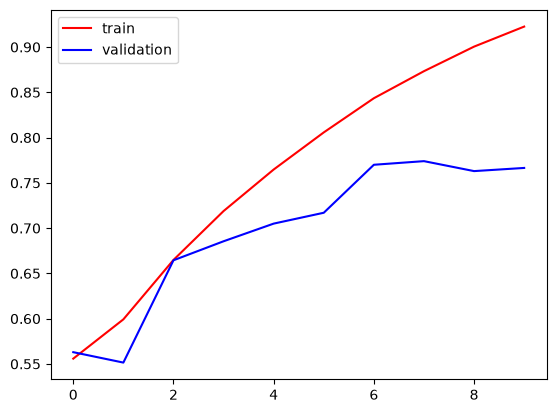

In [8]:
# import library to visualize the result
import matplotlib.pyplot as plt

plt.plot(history.history["accuracy"],color="red",label="train")
plt.plot(history.history["val_accuracy"],color="blue", label="validation")
plt.legend()
plt.show()

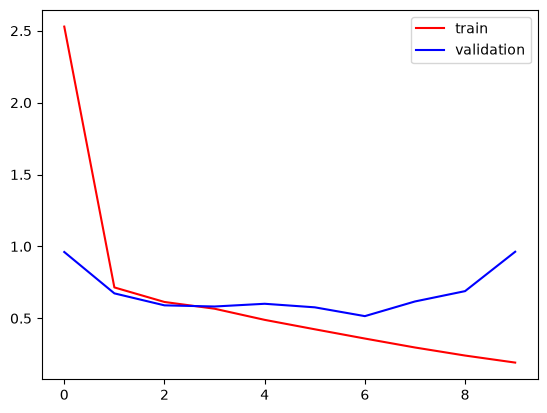

In [9]:
plt.plot(history.history["loss"],color="red",label="train")
plt.plot(history.history["val_loss"],color="blue", label="validation")
plt.legend()
plt.show()

##### ways to reduce overfitting
 
###### Add more data
###### Data Augmentation (from existing data create more data)
###### L1/L2 Regularization
###### Dropout
###### Batch Norm
###### Reduce Complexity

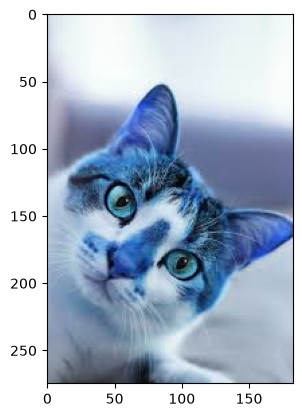

In [13]:
# import cv to check the result
import cv2

test_img = cv2.imread("cat.jpg")
plt.imshow(test_img)

In [14]:
test_img.shape

(275, 183, 3)

In [ ]:
import numpy as np
test_img = cv2.resize(test_img, (256, 256))

TypeError: 'numpy.ndarray' object is not callable

In [ ]:
test_input = test_img.reshape((1,256,256,3))

In [ ]:
model.predict(test_input)